In [28]:
import torch
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader
import matplotlib.pyplot as plt

numbers = torch.arange(1,1001,dtype=torch.float32)

feature1 = numbers
feature2 = numbers +1 

sequence_length = 10

X = []
y = []

for i in range(len(numbers)-sequence_length):

    f1 = feature1[i:i+sequence_length]
    f2 = feature2[i:i+sequence_length]

    # Shape: (10,2)
    sequence = torch.stack((f1,f2),dim=1)

    X.append(sequence)

    # Predict next number
    y.append(feature1[i+sequence_length])

X = torch.stack(X)
y = torch.stack(y)

print(X.shape)
print(y.shape)

torch.Size([990, 10, 2])
torch.Size([990])


In [29]:
print(X[0])
print(y[0])

tensor([[ 1.,  2.],
        [ 2.,  3.],
        [ 3.,  4.],
        [ 4.,  5.],
        [ 5.,  6.],
        [ 6.,  7.],
        [ 7.,  8.],
        [ 8.,  9.],
        [ 9., 10.],
        [10., 11.]])
tensor(11.)


In [30]:
from torch.utils.data import TensorDataset, DataLoader
X = X/1000.0
y = y/1000.0

dataset = TensorDataset(X, y)

train_loader = DataLoader(
    dataset,
    batch_size=32,
    shuffle=True
)
for inputs, targets in train_loader:

    print(inputs.shape)
    print(targets.shape)
    break

torch.Size([32, 10, 2])
torch.Size([32])


In [31]:
class TwoInputRNN(torch.nn.Module):

    def __init__(self):
        super().__init__()

        self.hidden_size = 64

        self.rnn = torch.nn.RNN(
            input_size=2,
            hidden_size=64,
            num_layers=1,
            batch_first=True
        )

        self.fc = torch.nn.Linear(64, 1)

    def forward(self, x):

        h0 = torch.zeros(
            1,
            x.size(0),
            self.hidden_size,
            device=x.device
        )

        out, _ = self.rnn(x, h0)

        # Last time step
        out = out[:, -1, :]

        out = self.fc(out)

        return out
model = TwoInputRNN()
print(model)    

TwoInputRNN(
  (rnn): RNN(2, 64, batch_first=True)
  (fc): Linear(in_features=64, out_features=1, bias=True)
)


Epoch  20  Loss = 0.00000365
Epoch  40  Loss = 0.00000324
Epoch  60  Loss = 0.00000284
Epoch  80  Loss = 0.00000456
Epoch 100  Loss = 0.00000097
Epoch 120  Loss = 0.00000128
Epoch 140  Loss = 0.00000024
Epoch 160  Loss = 0.00000039
Epoch 180  Loss = 0.00000017
Epoch 200  Loss = 0.00000008
Epoch 220  Loss = 0.00000027
Epoch 240  Loss = 0.00000031
Epoch 260  Loss = 0.00000871
Epoch 280  Loss = 0.00000117
Epoch 300  Loss = 0.00000394


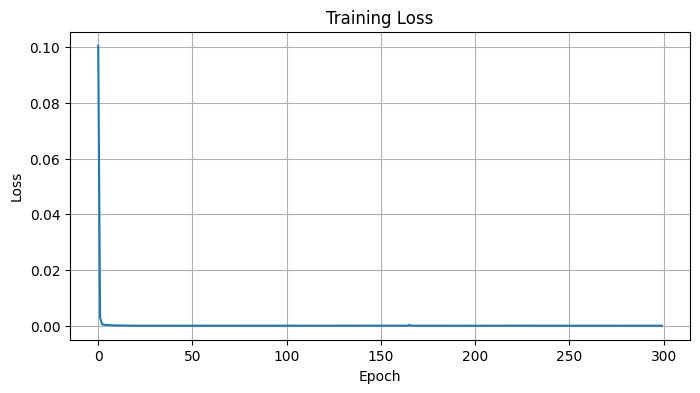

In [32]:
criterion = nn.MSELoss()

optimizer = optim.Adam(model.parameters(),
                       lr=0.001)

# -------------------------------------------------------
# Training
# -------------------------------------------------------

epochs = 300

loss_history = []

for epoch in range(epochs):

    running_loss = 0

    for inputs,targets in train_loader:

        targets = targets.unsqueeze(1)

        prediction = model(inputs)

        loss = criterion(prediction,targets)

        optimizer.zero_grad()

        loss.backward()

        optimizer.step()

        running_loss += loss.item()

    epoch_loss = running_loss/len(train_loader)

    loss_history.append(epoch_loss)

    if (epoch+1)%20==0:

        print(f"Epoch {epoch+1:3d}  Loss = {epoch_loss:.8f}")

# -------------------------------------------------------
# Plot Loss
# -------------------------------------------------------

plt.figure(figsize=(8,4))

plt.plot(loss_history)

plt.xlabel("Epoch")

plt.ylabel("Loss")

plt.title("Training Loss")

plt.grid(True)

plt.show()


In [33]:
feature1 = torch.arange(991, 1001, dtype=torch.float32)
feature2 = feature1 + 1

test = torch.stack((feature1, feature2), dim=1)

print(test.shape)
test = test / 1000.0
test = test.unsqueeze(0)

print(test.shape)

torch.Size([10, 2])
torch.Size([1, 10, 2])


In [34]:
model.eval()

with torch.no_grad():
    prediction = model(test)

# Convert back to the original scale
prediction = prediction.squeeze().item() * 1000

print("\nPredicted Next Number = %.2f" % prediction)
print("Expected Next Number  = 1001")


Predicted Next Number = 1001.52
Expected Next Number  = 1001
